# Radio-map extension v2: repaired data, robust trend, a regime where learning can win, clean statistics

**Needs next to it:** `rmbench_core.py`, `rmbench_nn.py`, `rmbench_ext.py`, `run_ext.py` (all four **unchanged**) and the new `rmbench_ext2.py`. Do not save the new file over `rmbench_ext.py`: `rmbench_ext2.py` imports `rmbench_ext`, so the two must be separate files.

**Status of numbers.** This file was written without being executed. The earlier runs (2 UJI floors, DeepMIMO narrowband, the original `TOPO`/`XFER` lists) are **exploratory**; no number from them is reused. Only contrasts written to `prereg.json` in section 6 are labelled **CONFIRMATORY**. Run it once with `SMOKE = True` first (fake UJI-format data + the synthetic simulator, no DeepMIMO) to check the plumbing.

| Your plan item | Where it is handled |
|---|---|
| 2a UJI has 2 floors, needs ~13 | §2 per-floor feasibility table, a builder whose `dropped` record is correct, and an assertion on the number of floors |
| 2b 15-label trend failure (27 dB) | §3 robust trend shared by every method (multi-start localisation, CV choice among constant / n=2 / fitted n, clipped to the label range) + before/after table |
| 2c more datasets / layouts | §4 second simulator with 12 wall layouts and building geometry, optional extra real fingerprint CSVs, optional extra DeepMIMO slugs |
| 3a smoother targets | §4 DeepMIMO `path_sum` (and optionally `channel`, `narrowband`), §5 noise-fraction table per target |
| 3b side information | `geo_side` features (LOS, wall count) for the GNNs **and** the fair classical comparator `rk_side` that sees the same covariates |
| 3c tuning | §7 `GCN_SPACE` / `KGNN_SPACE` tuned on units disjoint from the evaluation units (2-fold cross-fitting), then evaluated |
| 4a exploratory vs confirmatory | §6 hashed pre-registration written before any confirmatory run; fresh test-set salt + fresh replicates |
| 4b report every contrast | every contrast is printed and saved with CI, Holm p, direction (wins **and** losses) |
| 4c degenerate outage metrics | outage shown only where the target is predictable; classes must have >= 8 test points; absolute thresholds kept only if they split every layout |
| 4d both splits | `random` and `blocked` are separate pre-registered families, shown side by side |

## 1. Setup

In [1]:
import os, sys, json, warnings, shutil
sys.path.insert(0, os.getcwd())

# --- preflight: the notebook needs FIVE files next to it. rmbench_ext2.py must NOT be saved under the name rmbench_ext.py ---------
def _preflight():
    need = ["rmbench_core.py", "rmbench_nn.py", "rmbench_ext.py", "rmbench_ext2.py", "run_ext.py"]
    gone = [f for f in need if not os.path.exists(f)]
    if gone: raise FileNotFoundError(f"missing next to the notebook ({os.getcwd()}): {gone}")
    ext, ext2 = open("rmbench_ext.py").read(), open("rmbench_ext2.py").read()
    if "rmbench_ext as rx" in ext:       # only the second layer imports rmbench_ext
        raise RuntimeError("rmbench_ext.py contains the ext2 code (it imports itself -> circular import). Save that file as rmbench_ext2.py "
                           "and restore the ORIGINAL rmbench_ext.py (the one that defines H0, UJI_CFG, fetch_uji, run_tasks_ext, ...).")
    if "rmbench_ext as rx" not in ext2:
        raise RuntimeError("rmbench_ext2.py does not look like the second layer (it should do `import rmbench_core as rc, rmbench_ext as rx`).")
    if "H0" not in ext: raise RuntimeError("rmbench_ext.py does not define H0: wrong version of the file.")
_preflight()
for _m in ("rmbench_ext", "rmbench_ext2"): sys.modules.pop(_m, None)      # drop half-initialised modules left by an earlier failed import

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import rmbench_core as rc, rmbench_ext as rx, rmbench_ext2 as r2

SMOKE  = False         # True: ~10 min plumbing check on FAKE data. Says nothing about science. Wipes nb2_smoke/ each time.
N_JOBS = max(1, (os.cpu_count() or 2) - 1)
ROOT   = "nb2_smoke" if SMOKE else "results_ext2"
if SMOKE: shutil.rmtree(ROOT, ignore_errors=True)
os.makedirs(ROOT, exist_ok=True)

# families to run. "dm_channel" / "dm_nb" (narrowband) are optional extras; DeepMIMO needs the deepmimo package and network.
WANT = ["uji", "wall"] if SMOKE else ["uji", "wall", "dm_path"]

S = dict(n_layouts_wall=3 if SMOKE else 12, n_tx_wall=2 if SMOKE else 6, wall_pts=250 if SMOKE else 500,
         wall_dens=(20, 40, 60) if SMOKE else (20, 50, 100), wall_ntest=100 if SMOKE else 200,
         n_rep=2 if SMOKE else 5, trials=2 if SMOKE else 8, tune_rep=1 if SMOKE else 2, max_tune_units=8 if SMOKE else 40,
         pretrain_steps=60 if SMOKE else 1500, n_src=8 if SMOKE else 40, max_aps_per_floor=2 if SMOKE else 8,
         min_floors=6 if SMOKE else 13, min_floors_assert=4 if SMOKE else 10, max_dm_units=6 if SMOKE else 24)
print("SMOKE" if SMOKE else "REAL", "| jobs:", N_JOBS, "| families:", WANT)

REAL | jobs: 15 | families: ['uji', 'wall', 'dm_path']


## 2. Data A: UJIIndoorLoc, why floors disappear

Two code facts explain the 2-floor result without running anything: (1) a unit needs `min_unit_points = 110` reference points where the AP is detected in >= 50% of the captures, and the old test cell required `max density + n_test + 1 = 101`, so a floor survives only if some AP is seen at >= 110 reference points; (2) the old `dropped` list only contained APs that **passed** the point threshold but were cut by the per-floor cap, labelled "too few detected reference points", so it could never show why a building vanished.

The table below counts, per building-floor, how many APs clear each threshold (counts only, no model, no RMSE). The setting is then chosen by a fixed rule: the first candidate (strict detection rule first, larger test set first) under which `min_floors` floors keep at least 3 APs. The rule is in code, not tuned on results.

In [2]:
csv_dir = rx.make_fake_uji(f"{ROOT}/fake_uji", floors=(2, 2, 2), n_waps=12) if SMOKE else rx.fetch_uji("data/ujiindoorloc")
uji_df = r2.read_uji(csv_dir)
tab = r2.wifi_floor_table(uji_df, **r2.UJI_COLS)
base = tab[tab.det_frac == 0.5].drop_duplicates(["building", "floor"]).set_index(["building", "floor"])[["n_rows", "n_ref_points"]]
for fr in (0.5, 0.3):
    print(f"\nAPs detected at >= T reference points (a point counts if >= {fr:.0%} of its captures saw the AP); T = max density + n_test + 1 of each candidate, 110 = old setting")
    display(base.join(tab[tab.det_frac == fr].pivot_table(index=["building", "floor"], columns="min_points", values="n_aps")))
sug_table, SUG = r2.suggest_wifi_setting(tab, min_floors=S["min_floors"], min_aps=3)
display(sug_table)
old = tab[(tab.det_frac == 0.5) & (tab.min_points == 110)]
print(f"OLD setting (min_unit_points=110, det_frac=0.5): floors with >= 1 AP = {int((old.n_aps >= 1).sum())} of {len(old)}")
print("chosen:", SUG)


APs detected at >= T reference points (a point counts if >= 50% of its captures saw the AP); T = max density + n_test + 1 of each candidate, 110 = old setting


n_rows  n_ref_points    41    51    61    76    86   101  110
building floor                                                               
0        0        1137           131  16.0  10.0   5.0   0.0   0.0   0.0  0.0
         1        1564           258  45.0  38.0  29.0  22.0  16.0  10.0  7.0
         2        1608           215  40.0  33.0  26.0  14.0  10.0   3.0  0.0
         3        1476           152  20.0  13.0   9.0   6.0   2.0   0.0  0.0
1        0        1398           106   7.0   4.0   0.0   0.0   0.0   0.0  0.0
         1        1627           191  27.0  13.0   1.0   0.0   0.0   0.0  0.0
         2        1483           153  14.0   6.0   4.0   0.0   0.0   0.0  0.0
         3         995            94   0.0   0.0   0.0   0.0   0.0   0.0  0.0
2        0        1966            89  17.0  10.0   6.0   0.0   0.0   0.0  0.0
         1        2273           183  34.0  30.0  26.0  19.0  14.0   8.0  6.0
         2        1631           126  28.0  18.0  13.0  11.0   4.0   3.0  0.0
         3        2749           151  25.0  20.0  17.0  11.0   8.0   2.0  0.0
         4        1141           106  18.0  13.0   9.0   3.0   1.0   0.0  0.0


APs detected at >= T reference points (a point counts if >= 30% of its captures saw the AP); T = max density + n_test + 1 of each candidate, 110 = old setting


n_rows  n_ref_points    41    51    61    76    86   101   110
building floor                                                                
0        0        1137           131  19.0  14.0   6.0   0.0   0.0   0.0   0.0
         1        1564           258  47.0  38.0  33.0  23.0  20.0  10.0   9.0
         2        1608           215  45.0  39.0  31.0  19.0  16.0   4.0   0.0
         3        1476           152  22.0  15.0  12.0   6.0   3.0   0.0   0.0
1        0        1398           106   9.0   4.0   0.0   0.0   0.0   0.0   0.0
         1        1627           191  28.0  14.0   2.0   0.0   0.0   0.0   0.0
         2        1483           153  19.0   9.0   5.0   0.0   0.0   0.0   0.0
         3         995            94   0.0   0.0   0.0   0.0   0.0   0.0   0.0
2        0        1966            89  19.0  17.0   7.0   0.0   0.0   0.0   0.0
         1        2273           183  44.0  33.0  29.0  23.0  18.0  15.0  10.0
         2        1631           126  35.0  24.0  19.0  13.0   8.0   4.0   3.0
         3        2749           151  32.0  24.0  22.0  14.0  12.0   5.0   2.0
         4        1141           106  19.0  15.0  10.0   5.0   3.0   0.0   0.0

,dmax,n_test,det_frac,min_points,floors_with_aps,floors_total,aps_total
0,60,40,0.5,101,4,13,26
1,45,40,0.5,86,5,13,55
2,45,30,0.5,76,7,13,86
3,30,30,0.5,61,10,13,145
4,30,20,0.5,51,12,13,208
5,20,20,0.5,41,12,13,291
6,60,40,0.3,101,5,13,38
7,45,40,0.3,86,7,13,80
8,45,30,0.3,76,7,13,103
9,30,30,0.3,61,10,13,176


OLD setting (min_unit_points=110, det_frac=0.5): floors with >= 1 AP = 2 of 13
chosen: {'densities': (5, 10, 20), 'n_test': 20, 'min_unit_points': 41, 'min_det_frac': 0.3, 'floors_ok': 12, 'reached': False}


In [3]:
UJI = dict(rx.UJI_CFG, cache_dir=f"{ROOT}/cache_uji", densities=SUG["densities"], n_test=SUG["n_test"], min_unit_points=SUG["min_unit_points"],
           min_det_frac=SUG["min_det_frac"], uji_max_waps_per_floor=S["max_aps_per_floor"], n_rep=S["n_rep"],
           outage_q=(0.25, 0.5), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=1)   # seed 1: a different AP sample than the exploratory run (seed 0)
ok_uji, rec_uji = r2.build_wifi_units(uji_df, UJI, "uji", **r2.UJI_COLS)
display(rec_uji.assign(reason=rec_uji.reason.str.replace(r"\(.*\)", "", regex=True).str.strip()).groupby(["building", "floor", "reason"]).size().unstack(fill_value=0))
meta = pd.DataFrame([dict(unit=n, layout=(u := rx.get_unit_ext(n, UJI["cache_dir"]))["layout"], parent=u["parent"], n_pts=len(u["y"]), y_std=u["y"].std()) for n in ok_uji])
print(f"{len(ok_uji)} units | {meta.parent.nunique()} building-floors (statistical units) | {meta.layout.nunique()} buildings")
display(meta.groupby("layout").agg(units=("unit", "size"), floors=("parent", "nunique"), median_pts=("n_pts", "median"), y_std=("y_std", "mean")).round(2))
assert meta.parent.nunique() >= S["min_floors_assert"], ("Too few floors for any inference. Read the tables above: lower the candidate (max density, n_test) in "
        "r2.SETTINGS, or relax the detection rule. Do not run the confirmatory sections with n this small.")
FAMILY_DEFS = {"uji": dict(names=ok_uji, cfg=UJI, side=False, by="parent", infer=None, primary="f1_q25", transfer=dict(group_size=1, pre="geo"))}

reason          cut by per-floor cap  kept  too few detected points
building floor                                                     
0        0                        11     8                       93
         1                        39     8                      111
         2                        37     8                      126
         3                        14     8                      155
1        0                         1     8                      117
         1                        20     8                      135
         2                        11     8                      163
         3                         0     0                      138
2        0                        11     8                       66
         1                        36     8                       95
         2                        27     8                       83
         3                        24     8                      104
         4                        11     8                      114

96 units | 12 building-floors (statistical units) | 3 buildings


,units,floors,median_pts,y_std
layout,,,,
uji_b0,32,4,59.5,9.84
uji_b1,24,3,49.5,9.65
uji_b2,40,5,57.5,9.89


## 3. The 15-label failure (`trend` 27 dB vs `idw` 12.7 dB)

Why it happens: UJI access-point positions are unknown, so `view_for_split` localises each AP from the labeled points with a 4-parameter fit that is accepted if it beats a constant by 10% **in-sample**. At 15 labels that test is weak; a wrong AP position gives wrong distances, an exponent up to 6 and wild extrapolation, and every method inherits it through the shared trend.

The robust policy (`trend_policy="robust"`, used everywhere below): multi-start localisation; three candidate trends (constant, fixed exponent 2, fitted exponent) compared by K-fold CV **on the labeled points only**, with the transmitter re-localised inside each training fold; the simplest candidate within one standard error of the best is used; predictions are clipped to the range of the labels. `trend_policy="legacy"` reproduces the old behaviour, so the table below is a like-for-like before/after on the same labeled sets. This is a diagnostic on a few APs per floor with its own test salt (`dev`); it is labelled exploratory and is not part of the confirmatory set.

In [4]:
dev_units = [n for p, g in meta.groupby("parent") for n in g.unit.tolist()[:3]]
DEV_CFG = {**UJI, "split_mode": "blocked", "test_salt": "dev"}
r2.run_tasks2(r2.make_tasks2(dev_units, UJI["densities"], range(2), r2.trend_dev_jobs(), DEV_CFG, prefix="dev"), f"{ROOT}/dev_trend.jsonl", N_JOBS)
dev = rc.read_results(f"{ROOT}/dev_trend.jsonl")
display(rx.agg_metric(dev, "rmse").round(2))
print("trend chosen by CV (robust policy), count of task x job rows:")
display(dev[dev.name == "trend_robust"].groupby(["density", "trend_kind"]).size().unstack(fill_value=0))
pc_dev = r2.contrast_report(dev, r2.TREND_DEV_CONTRASTS, "rmse", "dev_trend", ROOT, confirmatory=False)

[run_tasks2] 216 tasks, 216 done, 0 to run (n_jobs=15) -> results_ext2/dev_trend.jsonl


name              gat_del_legacy  gat_del_robust  idw_legacy  idw_robust  \
scenario density                                                           
uji      5                 33.88           12.09       13.75       10.90   
         10                16.51           10.61       10.41        9.19   
         20                12.96            9.59        8.62        8.51   

name              krig_global_legacy  krig_global_robust  trend_const  \
scenario density                                                        
uji      5                     13.79               11.18        11.70   
         10                    10.49                9.11        11.16   
         20                     8.59                8.52        11.06   

name              trend_legacy  trend_robust  
scenario density                              
uji      5               60.83         11.70  
         10              23.80          9.56  
         20              21.79          8.98

trend chosen by CV (robust policy), count of task x job rows:


trend_kind,const,fit,fixed
density,,,
5,72,0,0
10,30,16,26
20,22,21,29



=== dev_trend | rmse | exploratory | 15 tests, Holm over all (delta>0: A better)
   scenario  density                   A                   B  n_units  mean_delta_db  ci_lo    ci_hi  rel_gain_pct  p_holm                              direction  underpowered
0       uji        5        trend_robust        trend_legacy       12         49.121  0.278  135.234        80.758   1.000  n.s., CI excludes 0 but Holm p >= .05         False
1       uji       10        trend_robust        trend_legacy       12         14.241  0.004   40.950        59.843   1.000  n.s., CI excludes 0 but Holm p >= .05         False
2       uji       20        trend_robust        trend_legacy       12         12.813 -0.545   38.727        58.797   1.000                    n.s., CI includes 0         False
3       uji        5          idw_robust          idw_legacy       12          2.850  0.676    5.469        20.721   0.679  n.s., CI excludes 0 but Holm p >= .05         False
4       uji       10          idw_robu

## 4. More layouts: a second simulator, optional real datasets, DeepMIMO targets

* **Second simulator** (`wall`): 12 random buildings (size, interior walls with doors, wall loss, path-loss exponent, shadowing all drawn per layout), 6 transmitters each. Side information = number of walls crossed and a LOS flag. **Parent = layout**, so the statistical unit is the building, and "layout" has 12 levels. It is my own simple simulator: it tells you whether a regime exists where side information helps a GNN, not how a real building behaves. The fair comparator is `rk_side` (same covariates, ridge + IDW), not plain IDW.
* **Optional real data**: any fingerprint CSV with building / floor / x / y / `WAP*` columns can be added through `EXTRA_REAL`. I found by search that UTSIndoorLoc (one building, 16 floors), the Tampere crowdsourced set and SODIndoorLoc (3 buildings, known AP positions) exist; I did **not** verify their file layouts or download links, so check the CSV header and fill the column names yourself.
* **DeepMIMO**: `path_sum` (the smooth earlier target) is on by default; `channel` and `narrowband` are optional. LOS is the side information there. Slugs other than `i1_2p5` and `i2_28b` are unverified; an unknown slug is reported, not fatal.

In [5]:
if "wall" in WANT:
    WALL = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_wall", densities=S["wall_dens"], n_test=S["wall_ntest"], n_rep=S["n_rep"], min_unit_points=300,
                outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=1)
    ok_wall = r2.build_wall_units(WALL, S["n_layouts_wall"], S["n_tx_wall"], seed=1, n_pts=S["wall_pts"])
    FAMILY_DEFS["wall"] = dict(names=ok_wall, cfg=WALL, side=True, by="layout", infer=None, primary="f1_q10", transfer=dict(group_size=3 if not SMOKE else 1, pre="side"))
    print(len(ok_wall), "wall units in", S["n_layouts_wall"], "layouts")

72 wall units in 12 layouts


In [6]:
# Optional extra REAL fingerprint datasets. Example (fill in after reading the CSV header):
# EXTRA_REAL = [dict(dataset="uts", csv="data/uts/UTS_training.csv", bcol="BuildingID", fcol="Floor", xcol="X", ycol="Y", wprefix="WAP", nodet=100)]
EXTRA_REAL = []
for spec in EXTRA_REAL:
    d = pd.read_csv(spec["csv"]); cols = {k: spec[k] for k in ("bcol", "fcol", "xcol", "ycol")}; kw = dict(wprefix=spec.get("wprefix", "WAP"), nodet=spec.get("nodet", 100))
    t = r2.wifi_floor_table(d, **cols, **kw); S2, sug = r2.suggest_wifi_setting(t, min_floors=1, min_aps=3); display(S2)
    cfg = dict(UJI, cache_dir=f"{ROOT}/cache_{spec['dataset']}", densities=sug["densities"], n_test=sug["n_test"], min_unit_points=sug["min_unit_points"], min_det_frac=sug["min_det_frac"])
    names, rec = r2.build_wifi_units(d, cfg, spec["dataset"], **cols, **kw)
    FAMILY_DEFS[f"real_{spec['dataset']}"] = dict(names=names, cfg=cfg, side=False, by="parent", infer=None, primary="f1_q25", transfer=None)
    print(spec["dataset"], len(names), "units")

In [7]:
DM_SCENARIOS = ["i1_2p5", "i2_28b", "i3_60"]     # i3_60 slug unverified; append more slugs here
DM_INFER = ["i1_2p5"]                            # scenarios with many transmitters; single-/two-transmitter scenarios stay descriptive
DM_TARGETS = {"dm_path": "path_sum", "dm_channel": "channel", "dm_nb": "narrowband"}
for tag, pdef in DM_TARGETS.items():
    if tag not in WANT: continue
    cfg = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_{tag}", power_def=pdef, outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=1)
    names, dropped = rx.build_dm_units(DM_SCENARIOS, cfg)
    for n, why in dropped: print(tag, "dropped:", n, "-", why)
    by = rx.layouts_of(names, cfg["cache_dir"]); names = [n for v in by.values() for n in v[:S["max_dm_units"]]]
    if names: FAMILY_DEFS[tag] = dict(names=names, cfg=cfg, side=True, by="parent", infer=DM_INFER, primary="f1_q10", transfer=None)
display(r2.layout_summary(FAMILY_DEFS))
n_real = len({rx.get_unit_ext(n, FAMILY_DEFS['uji']['cfg']['cache_dir'])['layout'] for n in FAMILY_DEFS['uji']['names']})
print(f"layout levels: real UJI buildings = {n_real}, wall simulator = {S['n_layouts_wall'] if 'wall' in FAMILY_DEFS else 0}, extra real datasets = {len(EXTRA_REAL)}")

Scenario "i1_2p5" already exists in /home/praaneshnair/gitProjects/prism/deepmimo_scenarios
Loading TXRX PAIR: TXset 2 (tx_idx 0) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 1) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 2) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 3) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 4) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 5) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 6) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 7) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 8) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 9) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 10) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 11) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 12) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 13) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXs

,units,parents,layouts
family,,,
dm_path,27,27,3
uji,96,12,3
wall,72,12,12


layout levels: real UJI buildings = 3, wall simulator = 12, extra real datasets = 0


## 5. What is predictable? Noise fraction and outage thresholds

**Noise fraction** = nugget / (nugget + partial sill) of an exponential variogram of the trend residual. Near 1 the target is mostly fading-like noise and no interpolator or GNN can win; near 0 it is spatially structured. It is descriptive (it uses the unit's own labels, feeds no method and no test).

**Outage thresholds.** The quantile thresholds (train-label percentile) are always defined. An absolute dBm threshold is kept only if **every** layout of the family has 10-90% of its points below it; otherwise it is dropped (this is what made `f1_abs77` constant). Outage tables are later shown only in cells where `idw` has skill >= 0.2 (skill = 1 - MSE / test-label variance), and a class needs >= 8 test points or the metric is NaN.

In [8]:
def take_per_layout(names, cache, k=8):
    by = rx.layouts_of(names, cache); return [n for v in by.values() for n in v[:k]]
PT = pd.concat([r2.predictability_table(take_per_layout(fd["names"], fd["cfg"]["cache_dir"]), fd["cfg"]["cache_dir"]).assign(family=tag) for tag, fd in FAMILY_DEFS.items()], ignore_index=True)
display(PT.groupby(["family", "layout"]).agg(units=("unit", "size"), y_std=("y_std", "mean"), resid_std=("resid_std", "mean"), noise_frac=("noise_frac", "mean"),
                                             share_const_trend=("trend", lambda s: (s == "const").mean())).round(2))
CANDS = (-95, -90, -85, -80, -77, -70, -60, -50)
for tag, fd in FAMILY_DEFS.items():
    tb = r2.abs_threshold_table(fd["names"], fd["cfg"]["cache_dir"], CANDS); fd["cfg"]["outage_abs_dbm"] = r2.pick_abs_thresholds(tb, CANDS)
    print(f"\n{tag}: fraction of points below each absolute threshold, per layout"); display(tb.round(2))
    print(f"  kept (split every layout into 10-90%):", fd["cfg"]["outage_abs_dbm"] or "none -> quantile thresholds only")

units  y_std  resid_std  noise_frac  share_const_trend
family  layout                                                          
dm_path i1_2p5        8   1.02       0.14        0.03               0.00
        i2_28b        1   1.52       1.56        0.02               1.00
        i3_60         2   1.24       1.20        0.35               0.50
uji     uji_b0        8  11.10       5.91        0.52               0.12
        uji_b1        8   8.36       5.98        0.28               0.12
        uji_b2        8  10.89       6.12        0.36               0.00
wall    wall_L00      6  18.01       8.29        0.13               0.00
        wall_L01      6  14.12       6.64        0.06               0.00
        wall_L02      6  11.04       6.94        0.04               0.00
        wall_L03      6  15.33       8.86        0.04               0.00
        wall_L04      6  15.15       9.61        0.02               0.00
        wall_L05      6  12.46       6.63        0.04               0.00
        wall_L06      6  11.82       6.96        0.05               0.00
        wall_L07      6  15.84       7.79        0.05               0.00
        wall_L08      6  11.89       6.05        0.12               0.00
        wall_L09      6  18.68       8.68        0.01               0.00
        wall_L10      6   9.17       5.08        0.15               0.00
        wall_L11      6  11.66       6.07        0.14               0.00


uji: fraction of points below each absolute threshold, per layout


,<-95,<-90,<-85,<-80,<-77,<-70,<-60,<-50
layout,,,,,,,,
uji_b0,0.00,0.06,0.20,0.36,0.46,0.68,0.86,0.95
uji_b1,0.02,0.10,0.26,0.42,0.53,0.71,0.89,0.98
uji_b2,0.01,0.12,0.33,0.53,0.61,0.76,0.90,0.97


  kept (split every layout into 10-90%): (-85, -80, -77, -70)

wall: fraction of points below each absolute threshold, per layout


,<-95,<-90,<-85,<-80,<-77,<-70,<-60,<-50
layout,,,,,,,,
wall_L00,0.06,0.09,0.16,0.24,0.27,0.41,0.63,0.78
wall_L01,0.00,0.00,0.02,0.11,0.19,0.35,0.54,0.76
wall_L02,0.00,0.00,0.00,0.01,0.02,0.07,0.28,0.61
wall_L03,0.02,0.04,0.08,0.13,0.18,0.31,0.53,0.75
wall_L04,0.00,0.02,0.05,0.10,0.12,0.22,0.39,0.64
wall_L05,0.00,0.00,0.00,0.02,0.04,0.08,0.27,0.54
wall_L06,0.00,0.00,0.00,0.02,0.05,0.16,0.41,0.69
wall_L07,0.03,0.06,0.11,0.19,0.23,0.32,0.57,0.79
wall_L08,0.00,0.00,0.00,0.02,0.05,0.16,0.43,0.73


  kept (split every layout into 10-90%): (-60, -50)

dm_path: fraction of points below each absolute threshold, per layout


,<-95,<-90,<-85,<-80,<-77,<-70,<-60,<-50
layout,,,,,,,,
i1_2p5,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0
i3_60,0.0,0.0,0.00,0.0,0.0,0.01,1.0,1.0
i2_28b,0.0,0.0,0.06,1.0,1.0,1.00,1.0,1.0


  kept (split every layout into 10-90%): none -> quantile thresholds only


## 6. Pre-registration (write once, before any confirmatory result)

Everything the confirmatory runs may use is frozen here: contrast lists, thresholds, densities, replicate ids, test-set salt, tuning protocol, which datasets, both splits, and the claims. The file is hashed; re-running the cell with the same plan is a no-op, and a different plan raises. **Commit `prereg.json` to git before running section 7.** What was designed after seeing exploratory output (the trend policy, the outage gating, the choice of datasets) is listed in the file itself.

Holm is applied separately within each (dataset, split, contrast list); the cap on the number of tests is computed from the list (contrasts x densities x inference scenarios) and an over-cap call raises.

In [9]:
def n_parents(fd): return len({rx.get_unit_ext(n, fd["cfg"]["cache_dir"])["parent"] for n in fd["names"]})
def n_layouts(fd): return len({rx.get_unit_ext(n, fd["cfg"]["cache_dir"])["layout"] for n in fd["names"]})
PREREG = dict(
    title="radio-map extension v2, confirmatory design",
    earlier_runs="exploratory (2 UJI floors, DeepMIMO narrowband, original TOPO/XFER lists). Not reused.",
    designed_after_seeing_exploratory=["robust trend policy (the 15-label failure)", "gated outage metrics and threshold choice", "cross-fitted tuning", "side-information comparator rk_side",
                                       "choice of datasets / second simulator"],
    test_salt="conf1", reps=list(range(100, 100 + S["n_rep"])), splits=["random", "blocked"], block_buffer=0.0, trend_policy="robust",
    tuning=dict(enabled=True, n_folds=2, n_trials=S["trials"], tune_rep=S["tune_rep"], max_tune_units=S["max_tune_units"], salt="tune",
                objective="mean over densities of unit-level mean RMSE on units disjoint (by parent, or by layout for wall) from the evaluation fold; trial 0 = defaults",
                spaces="rc.GCN_SPACE (no fset; +heads for GAT; no k for Delaunay) and rc.KGNN_SPACE"),
    contrasts_common=r2.CONTRASTS_COMMON, contrasts_side=r2.CONTRASTS_SIDE, contrasts_outage=r2.CONTRASTS_OUTAGE,
    contrasts_xfer_geo=r2.CONTRASTS_XFER_GEO, contrasts_xfer_side=r2.CONTRASTS_XFER_SIDE,
    outage=dict(min_skill=0.2, ref="idw", min_class=8, abs_threshold_rule="every layout has 10-90% below it"),
    transfer=dict(steps=S["pretrain_steps"], finetune_steps=30, n_src=S["n_src"]),
    families={t: dict(n_units=len(fd["names"]), n_parents=n_parents(fd), n_layouts=n_layouts(fd), densities=list(fd["cfg"]["densities"]), n_test=fd["cfg"]["n_test"],
                      outage_q=list(fd["cfg"]["outage_q"]), outage_abs_dbm=list(fd["cfg"]["outage_abs_dbm"]), side=fd["side"], infer=fd["infer"], primary=fd["primary"], by=fd["by"])
              for t, fd in FAMILY_DEFS.items()},
    holm="one family per (dataset, split, contrast list); cap = contrasts x densities x inference scenarios",
    claims=["H1: tuned GNNs (gcn_knn_tuned, gat_del_tuned) have lower RMSE than idw",
            "H2: in side-information families, side-information GNNs have lower RMSE than rk_side (the fair classical comparator), not just than idw",
            "H3: GNNs pre-trained on other layouts (xfer_*) have lower RMSE than idw at the held-out layout",
            "A superiority claim for GNNs is made only for a contrast that is significantly better after Holm in BOTH splits; every other outcome is reported as is."])
PRE_REC = r2.write_prereg(PREREG, f"{ROOT}/prereg.json")
PRE = r2.load_prereg(f"{ROOT}/prereg.json")
print("written", PRE_REC["created_utc"], "sha256", PRE_REC["sha256"][:16], "| families:", list(PRE["families"]))
display(pd.DataFrame(PRE["families"]).T)

written 2026-10-11T11:44:02.007441Z sha256 97162105f4e8359a | families: ['dm_path', 'uji', 'wall']


,by,densities,infer,n_layouts,n_parents,n_test,n_units,outage_abs_dbm,outage_q,primary,side
dm_path,parent,"[30, 100, 300]",[i1_2p5],3,27,1000,27,[],"[0.1, 0.25]",f1_q10,True
uji,parent,"[5, 10, 20]",None,3,12,20,96,"[-85, -80, -77, -70]","[0.25, 0.5]",f1_q25,False
wall,layout,"[20, 50, 100]",None,12,12,200,72,"[-60, -50]","[0.1, 0.25]",f1_q10,True


In [10]:
# compute budget (job rows) before you start the long cells
rows = []
for tag, fd in FAMILY_DEFS.items():
    nd, nr, ns = len(fd["cfg"]["densities"]), len(PRE["reps"]), len(PRE["splits"]); nb = 3 + (2 if fd["side"] else 0)
    ev = len(fd["names"]) * nd * nr * (len(r2.default_jobs(fd["side"])) + nb) * ns
    tu = min(PRE["tuning"]["max_tune_units"], len(fd["names"]) // 2) * nd * PRE["tuning"]["tune_rep"] * nb * PRE["tuning"]["n_trials"] * PRE["tuning"]["n_folds"] * ns
    rows.append(dict(family=tag, eval_job_rows=ev, tuning_job_rows=tu))
display(pd.DataFrame(rows))

,family,eval_job_rows,tuning_job_rows
0,uji,25920,23040
1,wall,30240,34560
2,dm_path,11340,12480


## 7. Confirmatory runs: cross-fitted tuning, then evaluation (random and blocked)

For every family and split: units are split into 2 folds by parent (by layout for `wall`); hyper-parameters for fold *f* are tuned on the other fold with a separate test salt, frozen, and applied to fold *f*, so no evaluation unit is ever tuned on. Evaluation uses fresh replicate ids (100+) and a fresh test-set salt. Everything is resumable from the JSONL files; `RUN_ONLY = ["wall"]` runs one family at a time.

In [11]:
RUN_ONLY = None
RESULTS, TUNED = {}, {}
for tag in PRE["families"]:
    if RUN_ONLY and tag not in RUN_ONLY: continue
    for split in PRE["splits"]:
        print(f"\n######## {tag} | {split}")
        RESULTS[(tag, split)], TUNED[(tag, split)] = r2.run_confirmatory(tag, FAMILY_DEFS[tag], split, ROOT, PRE, N_JOBS)
rows = [dict(family=t, split=s, fold=f, base=b, trial=v["trial"], tuned_rmse=v["score"], default_rmse=v["default_score"])
        for (t, s), bf in TUNED.items() for f, d in bf.items() for b, v in d.items()]
if rows: display(pd.DataFrame(rows).assign(gain_pct=lambda d: 100 * (d.default_rmse - d.tuned_rmse) / d.default_rmse).round(3))


######## dm_path | random
[run_tasks2] 78 tasks, 78 done, 0 to run (n_jobs=15) -> results_ext2/dm_path/tune_dm_path_random_f0.jsonl
[run_tasks2] 84 tasks, 84 done, 0 to run (n_jobs=15) -> results_ext2/dm_path/tune_dm_path_random_f1.jsonl
[run_tasks2] 405 tasks, 405 done, 0 to run (n_jobs=15) -> results_ext2/dm_path/dm_path_random.jsonl

######## dm_path | blocked
[run_tasks2] 78 tasks, 78 done, 0 to run (n_jobs=15) -> results_ext2/dm_path/tune_dm_path_blocked_f0.jsonl
[run_tasks2] 84 tasks, 84 done, 0 to run (n_jobs=15) -> results_ext2/dm_path/tune_dm_path_blocked_f1.jsonl
[run_tasks2] 405 tasks, 405 done, 0 to run (n_jobs=15) -> results_ext2/dm_path/dm_path_blocked.jsonl

######## uji | random
[run_tasks2] 240 tasks, 240 done, 0 to run (n_jobs=15) -> results_ext2/uji/tune_uji_random_f0.jsonl
[run_tasks2] 240 tasks, 240 done, 0 to run (n_jobs=15) -> results_ext2/uji/tune_uji_random_f1.jsonl
[run_tasks2] 1440 tasks, 1440 done, 0 to run (n_jobs=15) -> results_ext2/uji/uji_random.jsonl



,family,split,fold,base,trial,tuned_rmse,default_rmse,gain_pct
0,dm_path,random,0,gcn_knn,5,0.221,0.223,0.913
1,dm_path,random,0,gat_del,3,0.217,0.221,1.615
2,dm_path,random,0,kgnn,3,0.176,0.177,0.793
3,dm_path,random,0,gcn_knn_side,0,0.190,0.190,0.000
4,dm_path,random,0,gat_del_side,7,0.171,0.194,11.964
5,dm_path,random,1,gcn_knn,1,0.141,0.143,1.366
6,dm_path,random,1,gat_del,3,0.142,0.144,1.389
7,dm_path,random,1,kgnn,3,0.124,0.124,0.250
8,dm_path,random,1,gcn_knn_side,5,0.142,0.144,1.814
9,dm_path,random,1,gat_del_side,4,0.140,0.141,0.741


## 8. Results

Tables are parent-level means (replicates -> unit -> parent -> mean over parents). Every method appears in every table. Every contrast of the pre-registered list is printed, with bootstrap CI over parents and Holm-adjusted p, whether it is a win, a loss or a tie. `delta = RMSE_B - RMSE_A`, so a positive delta means A is better. Outage tables appear only in cells where the target is predictable (section 5) and say so where they do not.

In [12]:
PCS, ENTRIES = {}, []
for (tag, split), df in RESULTS.items():
    PCS[(tag, split)] = r2.report_family(df, tag, split, FAMILY_DEFS[tag], os.path.join(ROOT, tag), PRE)
    for k, pc in PCS[(tag, split)].items(): ENTRIES.append((tag, split, k, pc))


##### dm_path_random: 5670 job rows, 5670 ok, 0 failed

=== rmse, parent-level mean (all methods)
name              gat_del  gat_del_side  gat_del_side_tuned  gat_del_tuned  gcn_knn  gcn_knn_side  gcn_knn_side_tuned  gcn_knn_tuned    idw   kgnn  kgnn_tuned  krig_global  rk_side  trend
scenario density                                                                                                                                                                           
i1_2p5   30         0.117         0.116               0.119          0.118    0.120         0.119               0.116          0.122  0.107  0.100       0.099        0.100    0.101  0.169
         100        0.083         0.084               0.084          0.082    0.085         0.084               0.085          0.084  0.076  0.071       0.071        0.071    0.075  0.156
         300        0.063         0.063               0.063          0.063    0.065         0.065               0.065          0.065  0.059  0.055   

In [13]:
MASTER = r2.master_table(ENTRIES); MASTER.to_csv(f"{ROOT}/confirmatory_master.csv", index=False)
print(len(MASTER), "contrast rows saved to confirmatory_master.csv (all of them, losses included)")
m = MASTER[(MASTER.metric == "rmse") & MASTER.B.isin(["idw", "rk_side"]) & MASTER.A.str.contains("gcn|gat|kgnn")]
print("\nlearned model vs idw / rk_side: outcome counts over density cells")
display(m.groupby(["dataset", "split", "A", "B"]).direction.value_counts().unstack(fill_value=0))
print("\nrelative RMSE gain of A over B (%) with '*' = significant after Holm, random vs blocked side by side")
for tag in PRE["families"]:
    pcs = {s: PCS[(tag, s)]["main"] for s in PRE["splits"] if (tag, s) in PCS and len(PCS[(tag, s)]["main"])}
    if len(pcs) >= 1:
        print("\n", tag); display(rc.variant_table(pcs, [("gcn_knn_tuned", "idw"), ("gat_del_tuned", "idw"), ("kgnn_tuned", "idw"), ("krig_global", "idw")]))

375 contrast rows saved to confirmatory_master.csv (all of them, losses included)

learned model vs idw / rk_side: outcome counts over density cells


direction                                   A WORSE (Holm)  A better (Holm)  \
dataset split   A                  B                                          
dm_path blocked gat_del            idw                   0                0   
                gat_del_side       idw                   0                0   
                                   rk_side               0                0   
                gat_del_side_tuned rk_side               0                0   
                gat_del_tuned      idw                   0                0   
                gcn_knn            idw                   0                0   
                gcn_knn_side       rk_side               0                0   
                gcn_knn_side_tuned rk_side               0                0   
                gcn_knn_tuned      idw                   0                0   
                kgnn               idw                   0                3   
                kgnn_tuned         idw                   0                3   
        random  gat_del            idw                   3                0   
                gat_del_side       idw                   3                0   
                                   rk_side               3                0   
                gat_del_side_tuned rk_side               3                0   
                gat_del_tuned      idw                   3                0   
                gcn_knn            idw                   3                0   
                gcn_knn_side       rk_side               3                0   
                gcn_knn_side_tuned rk_side               3                0   
                gcn_knn_tuned      idw                   3                0   
                kgnn               idw                   0                3   
                kgnn_tuned         idw                   0                3   
uji     blocked gat_del            idw                   0                0   
                gat_del_tuned      idw                   0                0   
                gcn_knn            idw                   2                0   
                gcn_knn_tuned      idw                   0                0   
                kgnn               idw                   0                1   
                kgnn_tuned         idw                   0                1   
        random  gat_del            idw                   2                0   
                gat_del_tuned      idw                   2                0   
                gcn_knn            idw                   1                0   
                gcn_knn_tuned      idw                   0                0   
                kgnn               idw                   0                2   
                kgnn_tuned         idw                   0                1   
wall    blocked gat_del            idw                   0                0   
                gat_del_side       idw                   0                2   
                                   rk_side               0                0   
                gat_del_side_tuned rk_side               0                0   
                gat_del_tuned      idw                   0                0   
                gcn_knn            idw                   0                0   
                gcn_knn_side       rk_side               0                0   
                gcn_knn_side_tuned rk_side               1                0   
                gcn_knn_tuned      idw                   0                0   
                kgnn               idw                   0                2   
                kgnn_tuned         idw                   0                0   
        random  gat_del            idw                   3                0   
                gat_del_side       idw                   0                3   
                                   rk_side               3                0   
                gat_del_side_tuned rk_side        


relative RMSE gain of A over B (%) with '*' = significant after Holm, random vs blocked side by side

 dm_path


density                                    30       100      300
scenario contrast             variant                           
i1_2p5   gat_del_tuned vs idw blocked    -5.4%    +5.2%    -0.6%
                              random   -10.2%*   -7.4%*   -6.6%*
         gcn_knn_tuned vs idw blocked    -7.8%    -0.0%    -3.2%
                              random   -13.8%*  -10.3%*   -9.8%*
         kgnn_tuned vs idw    blocked   +3.3%*   +4.3%*   +2.9%*
                              random    +7.1%*   +6.9%*   +5.8%*
         krig_global vs idw   blocked    +3.2%   +9.0%*  +10.4%*
                              random    +6.4%*   +6.4%*    +3.4%


 uji


density                                    5       10      20
scenario contrast             variant                        
uji      gat_del_tuned vs idw blocked   -3.4%   -5.8%   -1.9%
                              random    -2.3%  -7.3%*  -6.1%*
         gcn_knn_tuned vs idw blocked   -8.6%   -3.6%   +0.2%
                              random    -3.2%   -4.1%   -3.3%
         kgnn_tuned vs idw    blocked  +3.0%*   +2.2%   +0.6%
                              random   +4.2%*   +2.7%   +1.3%
         krig_global vs idw   blocked   -4.5%   -0.8%   -1.4%
                              random    -4.0%   -0.7%   -0.7%


 wall


density                                    20      50      100
scenario contrast             variant                         
wall     gat_del_tuned vs idw blocked    -1.8%   -0.8%   +2.1%
                              random   -10.2%*  -8.2%*  -9.0%*
         gcn_knn_tuned vs idw blocked    -4.2%   -0.7%   +1.3%
                              random   -10.3%*  -8.7%*  -9.1%*
         kgnn_tuned vs idw    blocked    +4.7%   +3.6%   +2.6%
                              random    +6.0%*  +3.4%*  +2.7%*
         krig_global vs idw   blocked    +2.8%   +3.1%   +3.1%
                              random    +2.8%*   +1.4%  +1.5%*

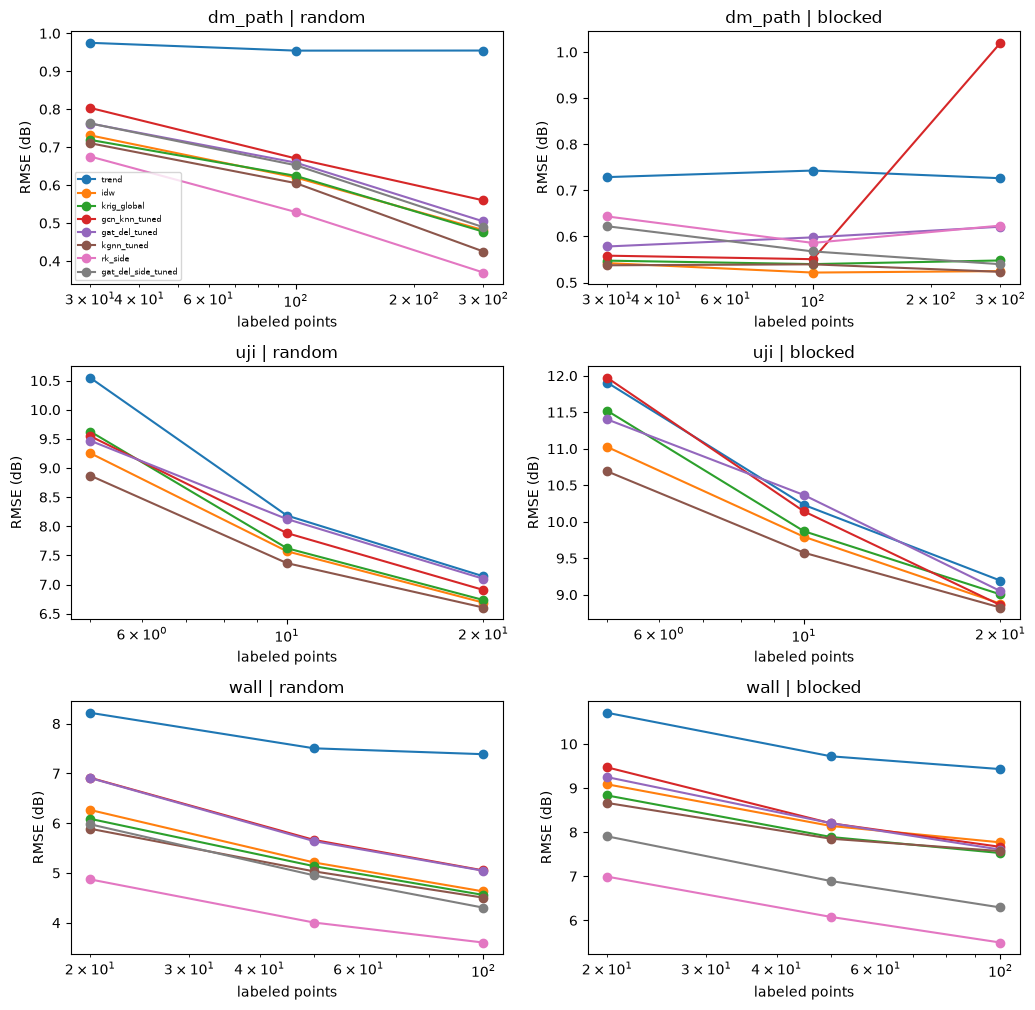

In [14]:
fig, axes = plt.subplots(len(PRE["families"]), len(PRE["splits"]), figsize=(5.2 * len(PRE["splits"]), 3.4 * len(PRE["families"])), squeeze=False)
for i, tag in enumerate(PRE["families"]):
    for j, split in enumerate(PRE["splits"]):
        if (tag, split) not in RESULTS: continue
        t = rx.agg_metric(RESULTS[(tag, split)], "rmse"); ax = axes[i][j]
        for m in [c for c in ["trend", "idw", "krig_global", "gcn_knn_tuned", "gat_del_tuned", "kgnn_tuned", "rk_side", "gat_del_side_tuned"] if c in t.columns]:
            g = t[m].groupby(level="density").mean(); ax.plot(g.index, g.values, marker="o", label=m)
        ax.set_xscale("log"); ax.set_title(f"{tag} | {split}"); ax.set_xlabel("labeled points"); ax.set_ylabel("RMSE (dB)")
axes[0][0].legend(fontsize=6); plt.tight_layout(); plt.show()

## 9. Cross-layout transfer (held-out layouts)

GNNs are pre-trained with episodic masked-label training on units of **other** layouts (`xfer_*`, zero-shot; `xferft_*`, +30 fine-tune steps) and applied to held-out layouts. UJI: leave-one-building-out, and each building is run as two halves of its floors so that the within-building control (`within_*`) is trained on floors the evaluation never touches. `wall`: groups of 3 layouts held out together. Inference is on the pooled `ALL` block (parents = floors for UJI, layouts for `wall`); per-layout rows are descriptive. Pre-training runs in the main process and is the slowest part: lower `pretrain_steps` in section 1 for a first pass.

In [15]:
XFER_RES, ENTRIES_X = {}, []
for tag, fd in FAMILY_DEFS.items():
    t = fd.get("transfer")
    if not t or (RUN_ONLY and tag not in RUN_ONLY): continue
    pre = r2.PRE_SIDE if t["pre"] == "side" else r2.PRE_GEO
    for split in PRE["splits"]:
        print(f"\n######## transfer {tag} | {split}")
        XFER_RES[(tag, split)] = r2.run_transfer(tag, fd, split, ROOT, PRE, N_JOBS, t["group_size"], pre)
for (tag, split), df in XFER_RES.items():
    C = PRE["contrasts_xfer_side"] if FAMILY_DEFS[tag]["side"] else PRE["contrasts_xfer_geo"]
    ENTRIES_X.append((tag, split, "xfer", r2.report_transfer(df, tag, split, os.path.join(ROOT, tag), C, PRE)))
MX = r2.master_table(ENTRIES_X)
if len(MX): MX.to_csv(f"{ROOT}/confirmatory_master_transfer.csv", index=False); display(MX.groupby(["dataset", "split", "A", "B"]).direction.value_counts().unstack(fill_value=0))


######## transfer uji | random
transfer plan (item, n_eval, n_cross_src, n_within_src): [('uji_b1#A', 16, 40, 8), ('uji_b1#B', 8, 40, 16), ('uji_b0#A', 16, 40, 16), ('uji_b0#B', 16, 40, 16), ('uji_b2#A', 24, 40, 16), ('uji_b2#B', 16, 40, 24)]
[run_tasks2] 1440 tasks, 990 done, 450 to run (n_jobs=15) -> results_ext2/uji/uji_xfer_random.jsonl
  25/450 11s failed jobs: 0
  50/450 15s failed jobs: 0
  75/450 18s failed jobs: 0
  100/450 21s failed jobs: 0
  125/450 24s failed jobs: 0
  150/450 27s failed jobs: 0
  175/450 30s failed jobs: 0
  200/450 33s failed jobs: 0
  225/450 36s failed jobs: 0
  250/450 39s failed jobs: 0
  275/450 42s failed jobs: 0
  300/450 45s failed jobs: 0
  325/450 49s failed jobs: 0
  350/450 52s failed jobs: 0
  375/450 54s failed jobs: 0
  400/450 58s failed jobs: 0
  425/450 61s failed jobs: 0
  450/450 63s failed jobs: 0

######## transfer uji | blocked
transfer plan (item, n_eval, n_cross_src, n_within_src): [('uji_b1#A', 16, 40, 8), ('uji_b1#B', 8, 40, 1

direction                                              A WORSE (Holm)  \
dataset split   A                   B                                   
uji     blocked xfer_gat_del        gat_del                         0   
                                    idw                             0   
                                    within_gat_del                  0   
                xfer_gcn_knn        gcn_knn                         0   
                                    idw                             0   
                                    within_gcn_knn                  0   
                xferft_gat_del      xfer_gat_del                    0   
                xferft_gcn_knn      xfer_gcn_knn                    0   
        random  xfer_gat_del        gat_del                         1   
                                    idw                             1   
                                    within_gat_del                  0   
                xfer_gcn_knn        gcn_knn                         1   
                                    idw                             1   
                                    within_gcn_knn                  0   
                xferft_gat_del      xfer_gat_del                    0   
                xferft_gcn_knn      xfer_gcn_knn                    0   
wall    blocked xfer_gat_del_side   gat_del_side                    0   
                                    idw                             0   
                                    rk_side                         0   
                xfer_gcn_knn_side   gcn_knn_side                    0   
                                    idw                             0   
                                    rk_side                         0   
                xferft_gat_del_side xfer_gat_del_side               0   
                xferft_gcn_knn_side xfer_gcn_knn_side               0   
        random  xfer_gat_del_side   gat_del_side                    0   
                                    idw                             0   
                                    rk_side                         2   
                xfer_gcn_knn_side   gcn_knn_side                    0   
                                    idw                             0   
                                    rk_side                         3   
                xferft_gat_del_side xfer_gat_del_side               0   
                xferft_gcn_knn_side xfer_gcn_knn_side               0   

direction                                              A better (Holm)  \
dataset split   A                   B                                    
uji     blocked xfer_gat_del        gat_del                          0   
                                    idw                              0   
                                    within_gat_del                   0   
                xfer_gcn_knn        gcn_knn                          0   
                                    idw                              0   
                                    within_gcn_knn                   0   
                xferft_gat_del      xfer_gat_del                     0   
                xferft_gcn_knn      xfer_gcn_knn                     0   
        random  xfer_gat_del        gat_del                          0   
                                    idw                              0   
                                    within_gat_del                   0   
                xfer_gcn_knn        gcn_knn                          0   
                                    idw                              0   
                                    within_gcn_knn                   0   
                xferft_gat_del      xfer_gat_del                     1   
                xferft_gcn_knn      xfer_gcn_knn                     2   
wall    blocked xfer_gat_del_side   gat_del_side                     1   
                                    idw                              3   
                                    r

## 10. Limitations and threats to validity

* **Not executed by the author of this file.** Run `SMOKE = True` first. The pure numeric parts of the new helpers (trend selection, localisation, wall simulator, split salt, `rk_side`, outage gating, pre-registration hashing, floor table) were smoke-tested on small numpy arrays with the torch parts stubbed; the neural code paths, DeepMIMO loading, the UCI download and the process pool were not run.
* **UJI floors:** how many floors survive is decided by section 2 from data counts. If the assertion fails, the data cannot support floor-level inference with these densities; do not weaken the assertion.
* **The second simulator is mine.** Wall counts and LOS are almost deterministic drivers of the loss, so side information is highly informative by construction. It shows whether a regime exists where a GNN with side information can beat methods without it; the fair comparison is `rk_side`, and a GNN that does not beat `rk_side` there has no advantage worth reporting. It says nothing about real buildings. UJI has no side information.
* **Layouts:** real layout levels are the 3 UJI buildings unless `EXTRA_REAL` is filled; the simulator adds 12 simulated levels, and the DeepMIMO scenarios confound layout and carrier frequency.
* **Tuning is parent-disjoint, not layout-disjoint** for UJI and DeepMIMO (sibling floors / transmitters of the same building can sit in the tuning fold). For `wall` it is layout-disjoint.
* **Exploratory leakage into design.** The trend policy, outage gating and dataset choice were designed after seeing exploratory results (listed in `prereg.json`). The confirmatory runs use new floors, a different AP sample (`seed=1`), a new test-set salt and new replicate ids, but the building geometry is the same real data as before.
* **Wi-Fi RSSI at 2.4/5 GHz with unknown AP positions** is not 6G; detection is censored, so coverage statements are conditional on detection.
* **Blocked split** uses `block_buffer = 0`: labeled points may sit right next to the test block.
* **Unverified:** the `i3_60` slug, the `narrowband` channel shape, and the file layouts of any extra real dataset.